# VERSÃO COMPLETA DO FACILITADOR · Parte H (nível avançado) com interpretação

O mesmo notebook, já executado com os pontos da equipa, com: 🔎 interpretação · 🗣️ o que dizer · respostas-modelo.
Para os pares rápidos e para continuar em casa. **Não partilhar.**

# Parte H (opcional) · Nível avançado: afinar, validar e guardar os modelos

**Workshop de Estudantes 2 · Projecto EYES TO EARTH (ETE)**

Para os pares que acabaram, para os facilitadores e para continuar em casa. Aqui fazemos o que um cientista de dados
faz depois do primeiro modelo: **validar a sério, afinar os hiperparâmetros, escolher o limiar, medir a importância
das pistas, ver quantos exemplos são precisos, guardar o modelo** e, na regressão, **validar no tempo** e medir o
alerta como os hidrólogos.

| Secção | O que se aprende | Tempo |
| --- | --- | --- |
| H0 | Juntar os pontos e as imagens de todos os anos | 2 min |
| H1.1 | Validação cruzada: ao acaso ou deixando um ano de fora | 5 min |
| H1.2 | Afinar os hiperparâmetros com uma grelha | 5 min |
| H1.3 | Precisão e sensibilidade (o relatório da classificação) | 3 min |
| H1.4 | A curva ROC e a escolha do limiar | 5 min |
| H1.5 | Que pistas importam (impureza e permutação) | 3 min |
| H1.6 | Quantos exemplos são precisos (curva de aprendizagem) | 5 min |
| H1.7 | Guardar o modelo e usá-lo noutro dia | 3 min |
| H2 | Quantos grupos no K-means (cotovelo e silhueta) | 5 min |
| H3 | Regressão: novas pistas, três modelos, validação no tempo, o alerta | 10 min |


| Sinal | Quer dizer |
| --- | --- |
| ▶️ | Corra a célula: clique nela e prima **Shift + Enter** |
| ✏️ | Edite: troque os `...` pela sua resposta e corra outra vez |
| ✍️ | Responda por escrito, na célula de texto logo abaixo (duplo clique para escrever) |
| ✅ | A célula verifica a sua resposta |


**Como trabalhar no Jupyter Notebook:** clique numa célula e prima **Shift + Enter** para a correr (sempre por
ordem, de cima para baixo). Enquanto corre aparece `[*]` à esquerda; quando acaba, aparece um número. Para
escrever uma resposta, faça duplo clique na célula de texto. Guarde com **Ctrl + S**.

## Célula 0 · Ligar as ferramentas ▶️

A mesma Célula 0 dos notebooks 2 e 3. Corra sem mudar nada.

In [1]:
# Célula 0 · ferramentas da aula: corra sem mudar nada ▶️
import os                                   # os: encontrar ficheiros no computador
import json                                 # json: ler a lista de pontos da equipa
import numpy as np                          # numpy: contas com tabelas de números (uma imagem é uma tabela)
import matplotlib.pyplot as plt             # matplotlib: desenhar mapas e gráficos
from sklearn.ensemble import RandomForestClassifier   # scikit-learn: o modelo Random Forest
from sklearn import metrics                 # scikit-learn: as notas do modelo (acerto, IoU, F1, Kappa, ROC-AUC)

BANDAS = ["azul", "verde", "vermelho", "nir", "swir"]
INDICES = ["ndwi", "mndwi", "ndvi"]
TERRENO = ["hand", "altitude", "declive"]
RAIO = 2                                    # cada ponto marcado vale um quadrado de 5 x 5 píxeis (150 m x 150 m)


def encontrar(nome):
    """Procura um ficheiro de dados na pasta dados/ (ao lado do notebook, ou uma pasta acima)."""
    for pasta in ["dados", os.path.join("..", "dados"), "."]:
        caminho = os.path.join(pasta, nome)
        if os.path.exists(caminho):
            return caminho
    raise FileNotFoundError(f"Não encontrei {nome}. Abra o Jupyter na pasta Workshop_2/2_pratica: "
                            "os dados estão em 2_pratica/dados.")


def carregar(nome):
    """Abre uma imagem (.npz): as 5 bandas em reflectância (0 a 1) e os índices NDWI, MNDWI e NDVI."""
    z = np.load(encontrar(nome))
    img = {banda: z[banda] / 10000 for banda in BANDAS}
    with np.errstate(divide="ignore", invalid="ignore"):
        img["ndwi"] = (img["verde"] - img["nir"]) / (img["verde"] + img["nir"])
        img["mndwi"] = (img["verde"] - img["swir"]) / (img["verde"] + img["swir"])
        img["ndvi"] = (img["nir"] - img["vermelho"]) / (img["nir"] + img["vermelho"])
    img["nuvem"] = z["nuvem"]                   # True onde há nuvem, sombra ou falta de dados
    img["zona"] = z["zona"]                     # True dentro do distrito de Marracuene, fora do mar
    for chave in ["data", "satelite", "epoca"]:
        img[chave] = str(z[chave])
    img["caudal_m3s"] = float(z["caudal_m3s"])
    return img


def juntar_terreno(img, extra):
    """Acrescenta as camadas de terreno (iguais em todas as datas) às características da imagem."""
    for chave in TERRENO:
        img[chave] = extra[chave]
    return img


def cor_natural(img, brilho=0.15):
    """Junta vermelho, verde e azul numa imagem a cores."""
    return np.clip(np.dstack([img["vermelho"], img["verde"], img["azul"]]) / brilho, 0, 1)


def ver_imagem(img, titulo="", agua=(), nao_agua=(), grelha=100):
    """Mostra a imagem a cores com linhas e colunas numeradas, e os pontos marcados (círculo = água, quadrado = não água)."""
    plt.figure(figsize=(9, 12))
    plt.imshow(cor_natural(img))
    for linha, coluna in agua:
        plt.plot(coluna, linha, "o", ms=9, mfc="cyan", mec="black")
    for linha, coluna in nao_agua:
        plt.plot(coluna, linha, "s", ms=9, mfc="orange", mec="black")
    plt.xticks(range(0, img["verde"].shape[1], grelha))
    plt.yticks(range(0, img["verde"].shape[0], grelha))
    plt.grid(alpha=0.5, color="white")
    plt.xlabel("coluna")
    plt.ylabel("linha")
    plt.title(titulo)
    plt.show()


def ver_zona(img, linha, coluna, tamanho=60):
    """Lupa: mostra uma zona pequena à volta de (linha, coluna), com grelha fina, para escolher pontos certos."""
    l0, c0 = max(linha - tamanho, 0), max(coluna - tamanho, 0)
    recorte = cor_natural(img)[l0:linha + tamanho, c0:coluna + tamanho]
    plt.figure(figsize=(7, 7))
    plt.imshow(recorte, extent=(c0 - 0.5, c0 + recorte.shape[1] - 0.5, l0 + recorte.shape[0] - 0.5, l0 - 0.5))
    plt.plot(coluna, linha, "+", ms=20, color="red")
    plt.grid(alpha=0.5, color="white")
    plt.xlabel("coluna")
    plt.ylabel("linha")
    plt.title(f"Lupa à volta da linha {linha}, coluna {coluna}")
    plt.show()


def tabela(img, caracteristicas):
    """Uma linha por píxel e uma coluna por característica: é assim que o modelo lê a imagem."""
    pilha = np.stack([img[c] for c in caracteristicas], axis=-1)
    return np.nan_to_num(pilha.reshape(-1, len(caracteristicas)))


def exemplos(img, agua, nao_agua, caracteristicas, raio=RAIO, grupos=False):
    """Transforma os pontos marcados em exemplos: X (as características) e y (1 = água, 0 = não água).
    raio: cada ponto vale um quadrado de (2 x raio + 1)² píxeis. grupos=True devolve também o número do ponto
    de cada píxel (para a validação cruzada por pontos, no nível avançado)."""
    pilha = np.nan_to_num(np.stack([img[c] for c in caracteristicas], axis=-1))
    X, y, g, nas_nuvens = [], [], [], 0
    for classe, pontos in ((1, agua), (0, nao_agua)):
        for linha, coluna in pontos:
            janela = (slice(max(linha - raio, 0), linha + raio + 1), slice(max(coluna - raio, 0), coluna + raio + 1))
            limpo = ~img["nuvem"][janela]
            if not limpo.any():
                nas_nuvens += 1
                continue
            X.append(pilha[janela][limpo])
            y.append(np.full(limpo.sum(), classe))
            g.append(np.full(limpo.sum(), len(g)))
    if nas_nuvens:
        print(f"Atenção: {nas_nuvens} ponto(s) caíram em nuvens ou fora da imagem e foram ignorados.")
    if grupos:
        return np.concatenate(X), np.concatenate(y), np.concatenate(g)
    return np.concatenate(X), np.concatenate(y)


def prever(modelo, img, caracteristicas):
    """A probabilidade de ser água (0 a 1), para cada píxel da imagem."""
    probabilidade = modelo.predict_proba(tabela(img, caracteristicas))[:, 1]
    return probabilidade.reshape(img["verde"].shape)


def notas(verdade, previsto, probabilidade=None):
    """As notas do modelo comparado com a verdade (1 = água, 0 = não água)."""
    r = {"acerto": metrics.accuracy_score(verdade, previsto),
         "IoU": metrics.jaccard_score(verdade, previsto),
         "F1": metrics.f1_score(verdade, previsto),
         "Kappa": metrics.cohen_kappa_score(verdade, previsto)}
    if probabilidade is not None:
        r["ROC-AUC"] = metrics.roc_auc_score(verdade, probabilidade)
    return r


def mostrar_notas(nome, r):
    print(f"{nome:28s}", "  ".join(f"{k} {v:.3f}" for k, v in r.items()))


def contar_erros(verdade, previsto):
    """A matriz de confusão em palavras: o que acertou e o que errou."""
    agua_certa = int(((verdade == 1) & (previsto == 1)).sum())
    terra_certa = int(((verdade == 0) & (previsto == 0)).sum())
    falso_alarme = int(((verdade == 0) & (previsto == 1)).sum())
    agua_perdida = int(((verdade == 1) & (previsto == 0)).sum())
    print(f"Água que o modelo encontrou (certo):      {agua_certa:8d} píxeis")
    print(f"Terra que o modelo disse terra (certo):   {terra_certa:8d} píxeis")
    print(f"Falsos alarmes (terra que disse água):    {falso_alarme:8d} píxeis")
    print(f"Água perdida (água que disse terra):      {agua_perdida:8d} píxeis")
    return agua_certa, terra_certa, falso_alarme, agua_perdida


print("Ferramentas prontas.")

Ferramentas prontas.


## ⚙️ Painel de configuração ▶️

Tudo o que se pode mudar está aqui. Com `"pontos_2026": "nossos"`, o notebook usa os pontos que o vosso par marcou na
Parte B (o notebook 2 guardou-os em `os_nossos_pontos.json`).

In [2]:
import pandas as pd                     # tabelas (como no notebook 3)

# ⚙️ PAINEL DE CONFIGURAÇÃO do nível avançado: mude aqui e volte a correr a secção que quer ver
CONFIG = {
    # os exemplos
    "caracteristicas": BANDAS + INDICES,       # as pistas de cada píxel
    "pontos_2026": "equipa",                   # "equipa" (15 + 15) ou "nossos" (os do vosso par, guardados no notebook 2)
    "anos": [2026, 2014, 2021, 2022, 2024, 2025],   # os anos com pontos da equipa
    # H1 · classificação: validação, afinação, limiar
    "partes_ao_acaso": 6,                      # validação cruzada ao acaso: em quantas partes se dividem os píxeis
    "grelha": {"n_estimators": [50, 100, 300], "max_depth": [None, 3, 8], "min_samples_leaf": [1, 5, 20]},
    "limiares": [0.1, 0.3, 0.5, 0.7, 0.9],     # os limiares de probabilidade a comparar
    "pontos_por_classe": [2, 4, 8, 15],        # a curva de aprendizagem
    "pasta_modelos": "modelos",                # onde se guardam os modelos treinados
    # H2 · K-means
    "k_maximo": 8,                             # o K-means de 2 até k_maximo grupos
    "amostra_silhueta": 5000,                  # píxeis para a silhueta (a conta é pesada)
    # H3 · regressão do caudal
    "dias_a_frente": 3,
    "ultimo_ano_de_treino": 2018,
    "pistas_base": ['caudal_m3s', 'chuva_7d_mm', 'chuva_14d_mm', 'chuva_30d_mm'],
    "pistas_novas": ["caudal_m3s", "caudal_ontem", "variacao_1d", "chuva_dia_mm", "chuva_7d_mm", "chuva_14d_mm", "chuva_30d_mm"],
    "limiar_alerta": 376,                      # o alerta laranja (m³/s)
    "partes_no_tempo": 5,                      # validação no tempo: em quantos blocos se divide o treino
    "semente": 0,
}
RESULTADOS = {}                               # cada secção guarda aqui os seus números (vão para a ficha do modelo)
print("Configuração pronta.")

Configuração pronta.


---
## H0 · Os pontos e as imagens de todos os anos ▶️

Juntamos os pontos da equipa de **6 anos** (2026 e os 5 anos da Parte D): cada píxel de exemplo fica a saber de que ano veio.

In [3]:
# H0 · Os pontos e as imagens de todos os anos ▶️
from sklearn.model_selection import KFold, LeaveOneGroupOut, cross_val_score, GridSearchCV

extra = dict(np.load(encontrar("camadas_extra.npz")))
equipa = json.load(open(encontrar("exemplos_da_equipa.json")))
pontos = {str(ano): equipa[str(ano)] for ano in CONFIG["anos"]}
if CONFIG["pontos_2026"] == "nossos":
    if os.path.exists("os_nossos_pontos.json"):
        pontos["2026"] = json.load(open("os_nossos_pontos.json"))
        print("2026: os pontos do vosso par (os_nossos_pontos.json)")
    else:
        print("Não encontrei os_nossos_pontos.json (o notebook 2 guarda-o no Passo B3): uso os pontos da equipa.")

imagens = {}
for ano in CONFIG["anos"]:
    nome = "incomati_2026_cheia.npz" if ano == 2026 else f"incomati_{ano}_chuvosa.npz"
    imagens[ano] = juntar_terreno(carregar(nome), extra)

CAR = CONFIG["caracteristicas"]
Xs, ys, anos_px = [], [], []
for ano in CONFIG["anos"]:
    X_a, y_a = exemplos(imagens[ano], pontos[str(ano)]["agua"], pontos[str(ano)]["nao_agua"], CAR)
    Xs.append(X_a)
    ys.append(y_a)
    anos_px.append(np.full(len(y_a), ano))
X_todos, y_todos, ano_todos = np.concatenate(Xs), np.concatenate(ys), np.concatenate(anos_px)
X26, y26 = Xs[0], ys[0]                              # só 2026 (como na prática)

cheia = imagens[2026]
teste = (extra["ems_2026"] >= 0) & ~cheia["nuvem"]   # o exame independente do Copernicus EMS
verdade = extra["ems_2026"][teste]
rio_certo = {ano: extra["verif_agua"] & ~imagens[ano]["nuvem"] for ano in CONFIG["anos"]}
print("Píxeis de exemplo por ano:", {int(a): int((ano_todos == a).sum()) for a in CONFIG["anos"]})

Píxeis de exemplo por ano: {2026: 738, 2014: 250, 2021: 249, 2022: 250, 2024: 250, 2025: 249}


---
# H1 · Classificação avançada (água ou não água)

## H1.1 · Validação cruzada: ao acaso ou deixando um ano de fora? ▶️

A **validação cruzada** faz vários exames em vez de um: divide os exemplos em partes, treina com todas menos uma e testa
nessa; repete até cada parte ter sido exame uma vez. Mas **como** se divide importa muito:
- **ao acaso**: os píxeis de cada ponto (vizinhos, quase iguais) caem no treino e no exame ao mesmo tempo: é como copiar;
- **deixando um ano de fora**: o modelo é testado num ano que nunca viu. É a pergunta do projecto.

Ao acaso (píxeis misturados): F1 0.997 ± 0.002
Deixando um ano de fora:      F1 0.959 (média)


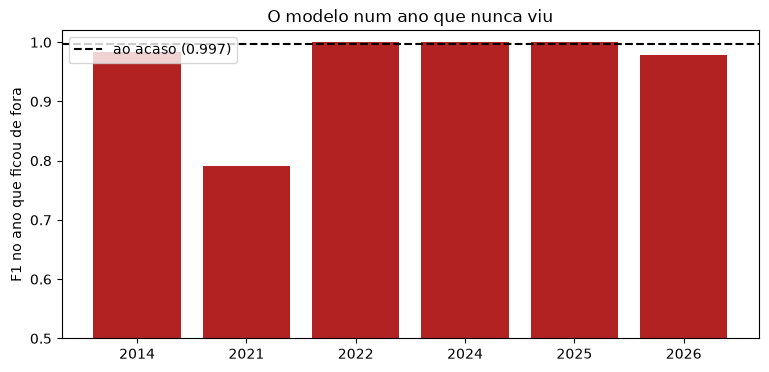

In [4]:
# H1.1 · Validação cruzada: ao acaso ou deixando um ano de fora? ▶️
floresta = RandomForestClassifier(n_estimators=100, random_state=CONFIG["semente"], n_jobs=-1)

ao_acaso = cross_val_score(floresta, X_todos, y_todos, scoring="f1",
                           cv=KFold(CONFIG["partes_ao_acaso"], shuffle=True, random_state=CONFIG["semente"]))
por_ano = cross_val_score(floresta, X_todos, y_todos, groups=ano_todos, cv=LeaveOneGroupOut(), scoring="f1")
anos_ordem = sorted(set(ano_todos.tolist()))
RESULTADOS["cv"] = {"ao_acaso": float(ao_acaso.mean()), "ao_acaso_dp": float(ao_acaso.std()),
                    "por_ano": {str(a): float(v) for a, v in zip(anos_ordem, por_ano)}, "por_ano_media": float(por_ano.mean())}

print(f"Ao acaso (píxeis misturados): F1 {ao_acaso.mean():.3f} ± {ao_acaso.std():.3f}")
print(f"Deixando um ano de fora:      F1 {por_ano.mean():.3f} (média)")
plt.figure(figsize=(9, 4))
plt.bar([str(a) for a in anos_ordem], por_ano, color="firebrick")
plt.axhline(ao_acaso.mean(), color="black", ls="--", label=f"ao acaso ({ao_acaso.mean():.3f})")
plt.ylim(0.5, 1.02)
plt.ylabel("F1 no ano que ficou de fora")
plt.title("O modelo num ano que nunca viu")
plt.legend()
plt.show()

🔎 **Interpretação.** Ao acaso: F1 0,997. Deixando um ano de fora: média 0,959 (2014: 0,984, 2021: 0,790, 2022: 1,000, 2024: 1,000, 2025: 1,000, 2026: 0,978).
A validação ao acaso é **optimista**: píxeis vizinhos do mesmo ponto vão para o treino e para o exame. Deixando um ano de fora
aparece o ponto fraco: **2021** (água barrenta que nenhum outro ano tem).

🗣️ **Resposta-modelo:** ao acaso, o exame tem píxeis quase iguais aos do treino (é copiar); 2021 é o mais difícil porque a água
barrenta desse ano não se parece com a dos outros anos.

✍️ **Pergunta:** porque é que a validação ao acaso dá uma nota quase perfeita? Que ano é o mais difícil, e porquê?

**Resposta-modelo:** Porque os píxeis de um mesmo ponto são quase iguais e vão uns para o treino e outros para o exame: é como copiar. Deixando um ano de fora, o mais difícil é 2021 (F1 0,79): água muito barrenta, diferente da dos outros anos.

## H1.2 · Afinar os hiperparâmetros com uma grelha ▶️

O `GridSearchCV` experimenta **todas** as combinações da grelha do painel (3 × 3 × 3 = 27) e dá a nota de cada uma com a
validação "um ano de fora". Demora cerca de 1 minuto.

In [5]:
# H1.2 · Afinar os hiperparâmetros com uma grelha (cerca de 1 minuto) ▶️
grelha = GridSearchCV(RandomForestClassifier(random_state=CONFIG["semente"], n_jobs=-1), CONFIG["grelha"],
                      cv=LeaveOneGroupOut(), scoring="f1")
grelha.fit(X_todos, y_todos, groups=ano_todos)       # experimenta TODAS as combinações, cada uma deixando um ano de fora

tabela_grelha = pd.DataFrame(grelha.cv_results_)[["params", "mean_test_score", "std_test_score"]]
tabela_grelha = tabela_grelha.sort_values("mean_test_score", ascending=False)
print("As 5 melhores combinações:")
print(tabela_grelha.head(5).round(3).to_string(index=False))
print("\nAs 3 piores:")
print(tabela_grelha.tail(3).round(3).to_string(index=False))
RESULTADOS["afinacao"] = {"melhores": grelha.best_params_, "f1_melhor": float(grelha.best_score_),
                          "f1_pior": float(tabela_grelha["mean_test_score"].min()),
                          "combinacoes": int(len(tabela_grelha))}

As 5 melhores combinações:
                                                         params  mean_test_score  std_test_score
   {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 300}            0.960           0.074
   {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100}            0.959           0.074
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 100}            0.959           0.076
   {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 100}            0.959           0.076
   {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 300}            0.959           0.076

As 3 piores:
                                                      params  mean_test_score  std_test_score
{'max_depth': 8, 'min_samples_leaf': 5, 'n_estimators': 300}            0.945           0.072
 {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 50}            0.945           0.072
{'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 300}            0.944           0.073


🔎 **Interpretação.** 27 combinações. Melhor: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 300} (F1 0,960); pior: F1 0,944.
A diferença é pequena: os botões mexem pouco. O que mudou a nota em 2021 foi dar exemplos desse ano (H1.6 e Parte D).
Árvores mais rasas (profundidade 3) generalizam um pouco melhor para anos novos: decoram menos.

✍️ **Pergunta:** quanto ganha a melhor combinação em relação à pior? O que ajuda mais: afinar os botões ou dar exemplos variados?

**Resposta-modelo:** Pouco: de F1 0,944 para 0,960. Dar exemplos variados (de outros anos) ajuda muito mais do que afinar os botões.

## H1.3 · O relatório da classificação: precisão e sensibilidade ▶️

- **precisão** da água: dos píxeis a que o modelo chamou água, quantos eram mesmo água (poucos falsos alarmes = precisão alta);
- **sensibilidade** (*recall*) da água: da água verdadeira, quanta o modelo encontrou (pouca água perdida = sensibilidade alta).

              precision    recall  f1-score   support

    não água      0.901     1.000     0.948     87455
        água      1.000     0.962     0.980    251954

    accuracy                          0.971    339409
   macro avg      0.950     0.981     0.964    339409
weighted avg      0.974     0.971     0.972    339409



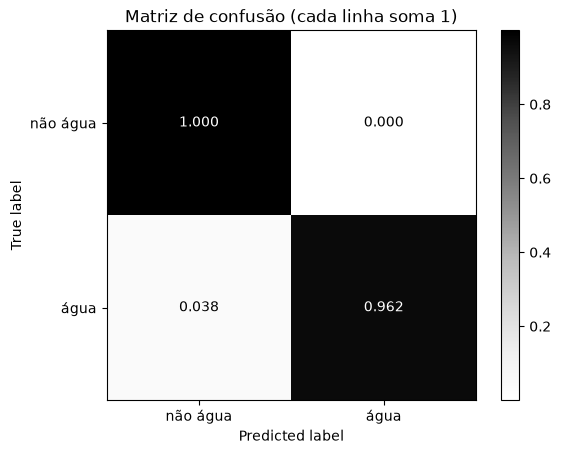

In [6]:
# H1.3 · O relatório da classificação: precisão e sensibilidade ▶️
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, roc_auc_score

modelo_2026 = RandomForestClassifier(n_estimators=100, random_state=CONFIG["semente"], n_jobs=-1).fit(X26, y26)
prob = prever(modelo_2026, cheia, CAR)
p_exame = prob[teste]
previsto = (p_exame > 0.5).astype(int)
print(classification_report(verdade, previsto, target_names=["não água", "água"], digits=3))
ConfusionMatrixDisplay.from_predictions(verdade, previsto, display_labels=["não água", "água"], normalize="true",
                                        cmap="Greys", values_format=".3f")
plt.title("Matriz de confusão (cada linha soma 1)")
plt.show()
rel = classification_report(verdade, previsto, output_dict=True)
RESULTADOS["relatorio"] = {"precisao_agua": rel["1"]["precision"], "sensibilidade_agua": rel["1"]["recall"],
                           "precisao_terra": rel["0"]["precision"], "sensibilidade_terra": rel["0"]["recall"]}

🔎 **Interpretação.** Água: precisão 1,000 (quase nenhum falso alarme) e sensibilidade 0,962
(perde cerca de 4% da água, nas bordas). Terra: precisão 0,901, sensibilidade 1,000.
O modelo é **conservador**: só diz água quando tem a certeza.

## H1.4 · A curva ROC e a escolha do limiar ▶️

O modelo dá uma **probabilidade**. O **limiar** decide a partir de quanto dizemos "água". Um limiar baixo encontra mais água,
mas dá mais falsos alarmes; um limiar alto faz o contrário. A **curva ROC** mostra todos os limiares de uma vez.

 limiar  falsos alarmes  água perdida   IoU
    0.1             523          5019 0.978
    0.3             275          7183 0.970
    0.5              29          9657 0.962
    0.7              25         12284 0.951
    0.9              22         14915 0.941


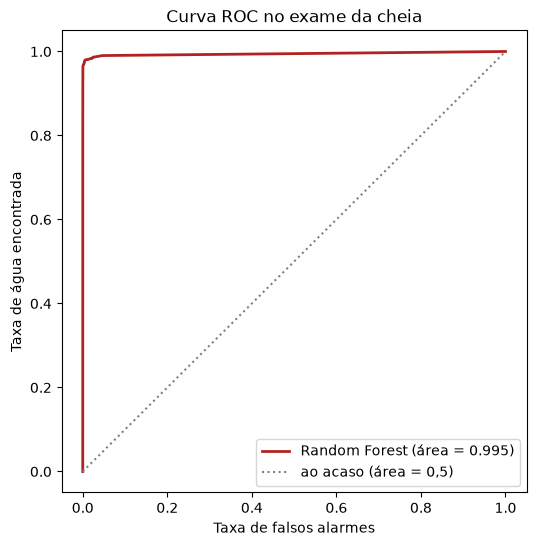

In [7]:
# H1.4 · A curva ROC e a escolha do limiar ▶️
fpr, tpr, _ = roc_curve(verdade, p_exame)
auc = roc_auc_score(verdade, p_exame)
linhas = []
for limiar in CONFIG["limiares"]:
    prev = (p_exame > limiar).astype(int)
    linhas.append({"limiar": limiar, "falsos alarmes": int(((verdade == 0) & (prev == 1)).sum()),
                   "água perdida": int(((verdade == 1) & (prev == 0)).sum()), "IoU": round(notas(verdade, prev)["IoU"], 3)})
tabela_limiares = pd.DataFrame(linhas)
print(tabela_limiares.to_string(index=False))

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, color="firebrick", lw=2, label=f"Random Forest (área = {auc:.3f})")
plt.plot([0, 1], [0, 1], color="gray", ls=":", label="ao acaso (área = 0,5)")
plt.xlabel("Taxa de falsos alarmes")
plt.ylabel("Taxa de água encontrada")
plt.title("Curva ROC no exame da cheia")
plt.legend(loc="lower right")
plt.show()
RESULTADOS["roc"] = {"auc": float(auc), "limiares": linhas}

🔎 **Interpretação.** Área sob a curva 0,995. Com limiar 0,5: 29 falsos alarmes e 9 657
píxeis de água perdida. Com 0,1: 523 falsos alarmes e só 5 019 de água perdida (IoU 0,978).
Nesta imagem, baixar o limiar até melhora o IoU.

🗣️ **Resposta-modelo:** num alerta de cheias, perder água (não avisar quem está em perigo) é pior; um limiar mais baixo é defensável,
desde que os falsos alarmes não façam as pessoas deixar de acreditar. É uma decisão humana, não do modelo.

✍️ **Pergunta:** para um sistema de **alerta de cheias**, que erro é pior: um falso alarme ou água perdida? Que limiar escolheriam?

**Resposta-modelo:** Para avisar a população, perder água é pior (não se avisa quem está em perigo). Um limiar mais baixo (0,3 ou mesmo 0,1) encontra mais água; o custo são mais falsos alarmes, que também têm de ser poucos para as pessoas continuarem a confiar.

## H1.5 · Que pistas importam? ▶️

- **impureza**: quanto cada pista foi usada pelas árvores para separar a água da terra;
- **permutação**: quanto a nota desce se **baralharmos** essa pista no exame (a pista deixa de fazer sentido).

          impureza (o que as árvores usaram)  permutação (o que se perde ao baralhar)
azul                                   0.016                                    0.000
verde                                  0.033                                    0.001
vermelho                               0.008                                   -0.001
nir                                    0.166                                    0.000
swir                                   0.218                                    0.001
ndwi                                   0.093                                    0.000
mndwi                                  0.278                                   -0.002
ndvi                                   0.187                                   -0.002


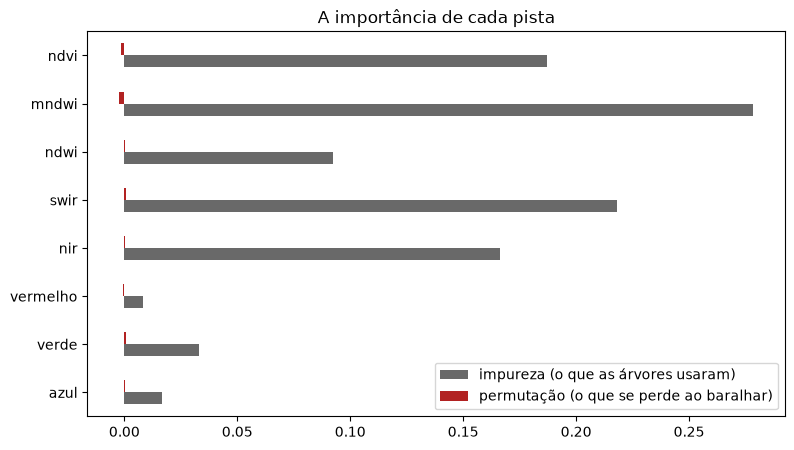

In [8]:
# H1.5 · Que pistas importam? Duas maneiras de medir ▶️
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(CONFIG["semente"])
amostra = rng.choice(len(verdade), 20000, replace=False)       # 20 000 píxeis do exame chegam
perm = permutation_importance(modelo_2026, tabela(cheia, CAR)[teste.ravel()][amostra], verdade[amostra],
                              n_repeats=5, random_state=CONFIG["semente"], scoring="f1", n_jobs=-1)
comparacao = pd.DataFrame({"impureza (o que as árvores usaram)": modelo_2026.feature_importances_,
                           "permutação (o que se perde ao baralhar)": perm.importances_mean}, index=CAR)
print(comparacao.round(3).to_string())
comparacao.plot.barh(figsize=(9, 5), color=["dimgray", "firebrick"])
plt.title("A importância de cada pista")
plt.show()
RESULTADOS["importancia"] = {"impureza": dict(zip(CAR, modelo_2026.feature_importances_.round(3).tolist())),
                             "permutacao": dict(zip(CAR, perm.importances_mean.round(4).tolist()))}

🔎 **Interpretação.** Pela impureza, as pistas mais usadas foram mndwi (0,28), swir (0,22), ndvi (0,19). Pela permutação, todas ficam
perto de 0: baralhar UMA pista não estraga nada, porque as outras dizem o mesmo (NIR, SWIR, NDWI e MNDWI são redundantes para a água).

🗣️ **Resposta-modelo:** as pistas são redundantes; quando uma é baralhada, o modelo usa as outras. Para medir pistas redundantes
tira-se o grupo inteiro de pistas e treina-se outra vez.

✍️ **Pergunta:** as árvores usaram muito o MNDWI e o SWIR, mas baralhar uma pista quase não faz descer a nota. Porquê?
(Pista: o NDWI, o MNDWI, o NIR e o SWIR dizem quase a mesma coisa sobre a água.)

**Resposta-modelo:** Porque as pistas são redundantes: NIR, SWIR, NDWI e MNDWI dizem quase o mesmo sobre a água. Quando uma é baralhada, as árvores usam as outras.

## H1.6 · Quantos exemplos são precisos? ▶️

 pontos por classe  IoU exame 2026  rio de 2021 (%)
                 2           0.977             57.0
                 4           0.977             57.5
                 8           0.976             58.9
                15           0.962             45.8

Com os 15 + 15 de 2026 e mais 5 + 5 de 2021: IoU 0.985 | rio de 2021 89.4%


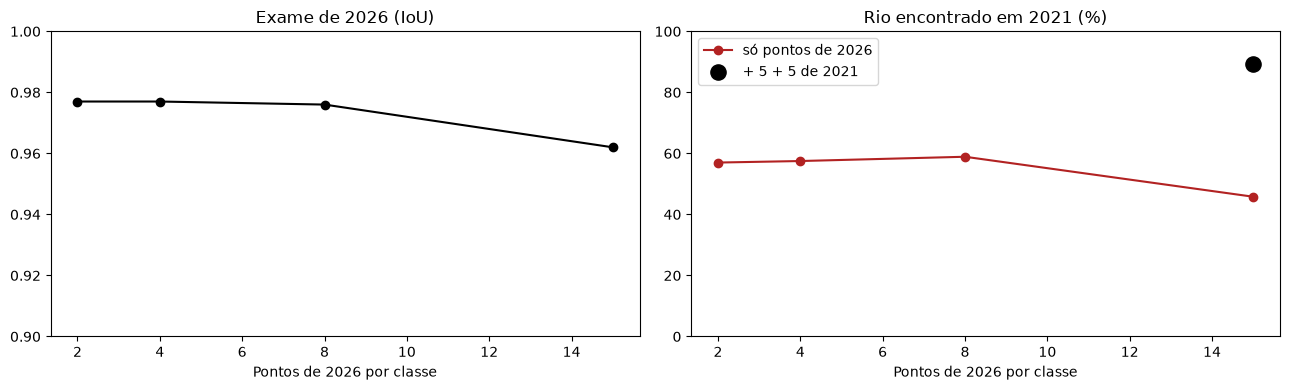

In [9]:
# H1.6 · Quantos exemplos são precisos? A curva de aprendizagem ▶️
img21 = imagens[2021]
curva = []
for n in CONFIG["pontos_por_classe"]:
    X_n, y_n = exemplos(cheia, pontos["2026"]["agua"][:n], pontos["2026"]["nao_agua"][:n], CAR)
    m = RandomForestClassifier(n_estimators=100, random_state=CONFIG["semente"], n_jobs=-1).fit(X_n, y_n)
    iou = notas(verdade, (prever(m, cheia, CAR)[teste] > 0.5).astype(int))["IoU"]
    rio21 = 100 * (prever(m, img21, CAR)[rio_certo[2021]] > 0.5).mean()
    curva.append({"pontos por classe": n, "IoU exame 2026": round(iou, 3), "rio de 2021 (%)": round(rio21, 1)})
# e se juntarmos 5 + 5 pontos de 2021?
X21, y21 = exemplos(img21, pontos["2021"]["agua"], pontos["2021"]["nao_agua"], CAR)
m = RandomForestClassifier(n_estimators=100, random_state=CONFIG["semente"], n_jobs=-1).fit(np.concatenate([X26, X21]), np.concatenate([y26, y21]))
com_2021 = {"IoU exame 2026": round(notas(verdade, (prever(m, cheia, CAR)[teste] > 0.5).astype(int))["IoU"], 3),
            "rio de 2021 (%)": round(100 * (prever(m, img21, CAR)[rio_certo[2021]] > 0.5).mean(), 1)}
tabela_curva = pd.DataFrame(curva)
print(tabela_curva.to_string(index=False))
print(f"\nCom os 15 + 15 de 2026 e mais 5 + 5 de 2021: IoU {com_2021['IoU exame 2026']} | rio de 2021 {com_2021['rio de 2021 (%)']}%")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(tabela_curva["pontos por classe"], tabela_curva["IoU exame 2026"], "o-", color="black")
eixos[0].set_ylim(0.9, 1)
eixos[0].set_title("Exame de 2026 (IoU)")
eixos[1].plot(tabela_curva["pontos por classe"], tabela_curva["rio de 2021 (%)"], "o-", color="firebrick", label="só pontos de 2026")
eixos[1].scatter([max(CONFIG["pontos_por_classe"])], [com_2021["rio de 2021 (%)"]], s=120, color="black", zorder=3, label="+ 5 + 5 de 2021")
eixos[1].set_ylim(0, 100)
eixos[1].set_title("Rio encontrado em 2021 (%)")
eixos[1].legend()
for e in eixos:
    e.set_xlabel("Pontos de 2026 por classe")
plt.tight_layout()
plt.show()
RESULTADOS["curva_aprendizagem"] = {"pontos": curva, "com_2021": com_2021}

🔎 **Interpretação.** 2 + 2 pontos: IoU 0,977, rio de 2021 57%; 4 + 4 pontos: IoU 0,977, rio de 2021 58%; 8 + 8 pontos: IoU 0,976, rio de 2021 59%; 15 + 15 pontos: IoU 0,962, rio de 2021 46%.
Com 2 + 2 pontos de 2026 o exame já é quase perfeito: a água desta imagem é fácil. **Mais pontos do mesmo tipo não ajudam 2021.**
Com 5 + 5 pontos de 2021, o rio de 2021 sobe para 89%.

🗣️ **Resposta-modelo:** mais exemplos iguais não ensinam nada de novo; o que ajuda é variedade (exemplos do tipo de água que falha).

✍️ **Pergunta:** mais pontos de 2026 melhoram o modelo em 2021? O que o melhora?

**Resposta-modelo:** Não: com 2 + 2 ou 15 + 15 pontos de 2026, o rio de 2021 fica entre 46% e 59%. O que melhora 2021 são 5 + 5 pontos de 2021 (89%): variedade, não quantidade.

## H1.7 · Guardar o modelo e usá-lo noutro dia ▶️

Um modelo treinado é um ficheiro: guarda-se com `joblib` e abre-se noutro dia, sem treinar outra vez. Junto vai uma **ficha
do modelo** (`.json`) com as pistas, os exemplos e as notas: é assim que se documenta um modelo a sério.

Guardado: modelos/floresta_agua_2026.joblib e a ficha do modelo (.json)


O modelo reaberto, na imagem de 2025-01-24: encontra 86.0% do rio


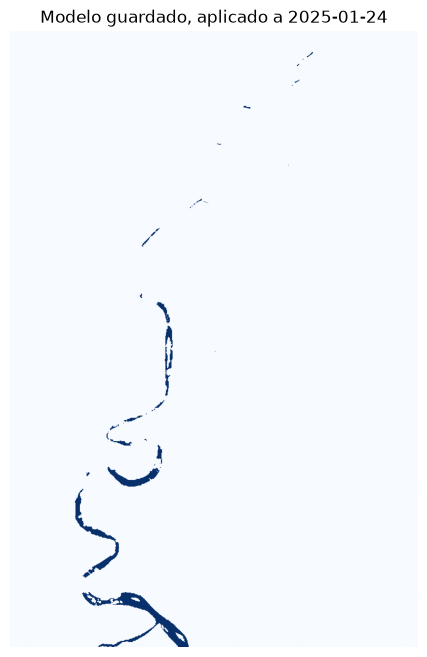

In [10]:
# H1.7 · Guardar o modelo e usá-lo noutro dia ▶️
import joblib                                     # guarda e abre modelos do scikit-learn
from datetime import datetime

os.makedirs(CONFIG["pasta_modelos"], exist_ok=True)
caminho = os.path.join(CONFIG["pasta_modelos"], "floresta_agua_2026.joblib")
joblib.dump(modelo_2026, caminho)                 # GUARDAR: o modelo inteiro num ficheiro
ficha = {"modelo": "Random Forest (100 árvores)", "treinado_em": datetime.now().isoformat(timespec="seconds"),
         "caracteristicas": CAR, "pontos_2026": CONFIG["pontos_2026"], "exemplos": int(len(y26)),
         "exame_ems_2026": {k: round(v, 3) for k, v in notas(verdade, previsto).items()}}
with open(caminho.replace(".joblib", "_ficha.json"), "w") as ficheiro:
    json.dump(ficha, ficheiro, ensure_ascii=False, indent=1)
print("Guardado:", caminho, "e a ficha do modelo (.json)")

reaberto = joblib.load(caminho)                   # ABRIR: noutro dia, noutro computador
img25 = imagens[2025]
p25 = prever(reaberto, img25, CAR)
rio25 = 100 * (p25[rio_certo[2025]] > 0.5).mean()
print(f"O modelo reaberto, na imagem de {img25['data']}: encontra {rio25:.1f}% do rio")
plt.figure(figsize=(6, 8))
plt.imshow((p25 > 0.5) & img25["zona"] & ~img25["nuvem"], cmap="Blues")
plt.title(f"Modelo guardado, aplicado a {img25['data']}")
plt.axis("off")
plt.show()
RESULTADOS["modelo_guardado"] = {"rio_2025": float(rio25)}

🔎 **Interpretação.** O modelo fica em `modelos/floresta_agua_2026.joblib`, com a ficha `.json`. Reaberto, encontra
86,0% do rio na imagem de 2025, igual ao modelo original: guardar não muda nada.

---
# H2 · Agrupamento avançado: quantos grupos?

No K-means, somos nós que escolhemos K. Duas ajudas clássicas:
- **cotovelo**: a inércia (a distância dos píxeis ao seu centro) desce sempre com K; procura-se o "cotovelo", onde deixa de descer muito;
- **silhueta**: de −1 a 1, quanto cada píxel está mais perto do seu grupo do que do grupo vizinho; quanto maior, melhor.

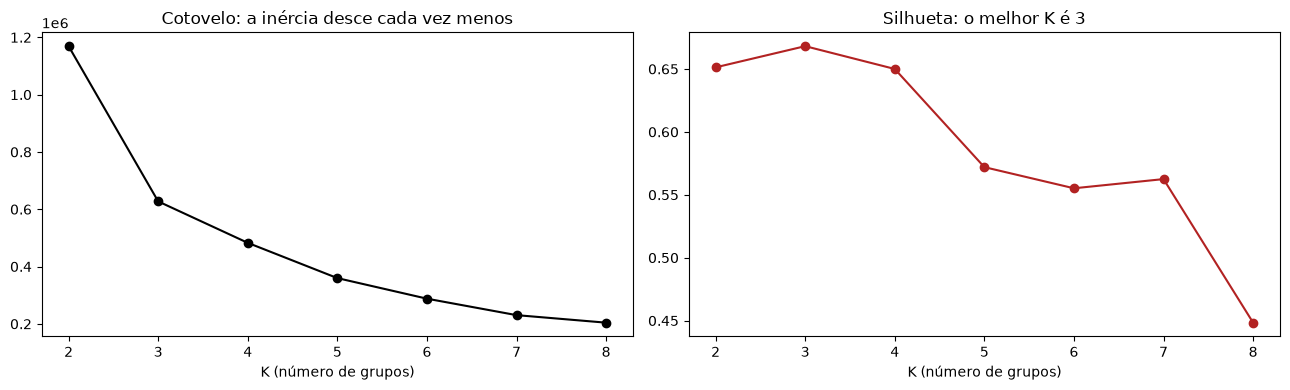

Silhueta por K: {2: 0.651, 3: 0.668, 4: 0.65, 5: 0.572, 6: 0.555, 7: 0.562, 8: 0.448}


In [11]:
# H2 · Quantos grupos? O método do cotovelo e a silhueta ▶️
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

valido = (cheia["zona"] & ~cheia["nuvem"]).ravel()
T = StandardScaler().fit_transform(tabela(cheia, CAR)[valido])     # as pistas na mesma escala
rng = np.random.default_rng(CONFIG["semente"])
amostra = T[rng.choice(len(T), CONFIG["amostra_silhueta"], replace=False)]
ks, inercia, silhueta = list(range(2, CONFIG["k_maximo"] + 1)), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=3, random_state=CONFIG["semente"]).fit(T)
    inercia.append(km.inertia_)                                     # quanto os píxeis ficam longe do seu centro
    silhueta.append(silhouette_score(amostra, km.predict(amostra))) # quanto os grupos ficam bem separados (1 = perfeito)
melhor_k = ks[int(np.argmax(silhueta))]
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(ks, inercia, "o-", color="black")
eixos[0].set_title("Cotovelo: a inércia desce cada vez menos")
eixos[1].plot(ks, silhueta, "o-", color="firebrick")
eixos[1].set_title(f"Silhueta: o melhor K é {melhor_k}")
for e in eixos:
    e.set_xlabel("K (número de grupos)")
plt.tight_layout()
plt.show()
print("Silhueta por K:", {k: round(s, 3) for k, s in zip(ks, silhueta)})
RESULTADOS["kmeans"] = {"silhueta": {str(k): round(float(s), 3) for k, s in zip(ks, silhueta)}, "melhor_k": melhor_k}

🔎 **Interpretação.** Silhueta: K = 2: 0,651, K = 3: 0,668, K = 4: 0,650, K = 5: 0,572, K = 6: 0,555, K = 7: 0,562, K = 8: 0,448. A melhor é K = 3; o cotovelo também fica perto de 3 a 4.
Bate com a prática: com K = 3 ou 4, a água fica num só grupo.

---
# H3 · Regressão avançada: o caudal daqui a 3 dias

Juntamos duas pistas novas (o caudal de ontem e a variação de um dia: o rio está a subir?), comparamos três modelos e
validamos **no tempo** (treina-se no passado e testa-se no bloco seguinte, nunca ao contrário). No exame (2019 a 2026)
medimos também o **alerta laranja** como os hidrólogos: **POD** (a parte dos dias de alerta que o modelo apanhou) e
**FAR** (a parte dos alertas do modelo que eram falsos). O **NSE** dos hidrólogos é o mesmo que o R².

                modelo  MAE validação (treino)  MAE exame  NSE / R² exame  POD laranja  FAR laranja
        recta (linear)                    19.6       26.1            0.73         0.64         0.20
floresta (300 árvores)                    15.4       28.7            0.62         0.74         0.33
  gradiente (boosting)                    16.3       30.0            0.61         0.73         0.35

POD = parte dos dias de alerta laranja que o modelo apanhou; FAR = parte dos alertas do modelo que eram falsos.


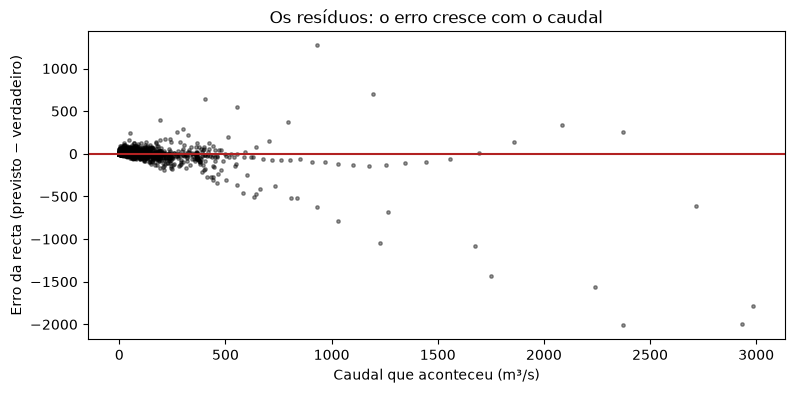

In [12]:
# H3 · Regressão avançada: novas pistas, três modelos, validação no tempo e o alerta ▶️
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

serie = pd.read_csv(encontrar("caudal_e_chuva_diarios.csv"), parse_dates=["data"])
serie["caudal_ontem"] = serie["caudal_m3s"].shift(1)                     # NOVA pista: o caudal de ontem
serie["variacao_1d"] = serie["caudal_m3s"] - serie["caudal_ontem"]       # NOVA pista: o rio está a subir ou a descer?
serie["caudal_futuro"] = serie["caudal_m3s"].shift(-CONFIG["dias_a_frente"])
serie = serie.dropna()
treino = serie[serie["data"].dt.year <= CONFIG["ultimo_ano_de_treino"]]
exame = serie[serie["data"].dt.year > CONFIG["ultimo_ano_de_treino"]]
PISTAS = CONFIG["pistas_novas"]

modelos_reg = {"recta (linear)": LinearRegression(),
               "floresta (300 árvores)": RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=CONFIG["semente"], n_jobs=-1),
               "gradiente (boosting)": HistGradientBoostingRegressor(random_state=CONFIG["semente"])}
linhas = []
for nome, m in modelos_reg.items():
    cv = cross_validate(m, treino[PISTAS], treino["caudal_futuro"], cv=TimeSeriesSplit(CONFIG["partes_no_tempo"]),
                        scoring="neg_mean_absolute_error")            # validação NO TEMPO: treina no passado, testa no bloco seguinte
    m.fit(treino[PISTAS], treino["caudal_futuro"])
    prev = m.predict(exame[PISTAS])
    verdadeiro = exame["caudal_futuro"].to_numpy()
    o, p = verdadeiro >= CONFIG["limiar_alerta"], prev >= CONFIG["limiar_alerta"]
    linhas.append({"modelo": nome, "MAE validação (treino)": round(-cv["test_score"].mean(), 1),
                   "MAE exame": round(metrics.mean_absolute_error(verdadeiro, prev), 1),
                   "NSE / R² exame": round(metrics.r2_score(verdadeiro, prev), 2),
                   "POD laranja": round((o & p).sum() / max(o.sum(), 1), 2),
                   "FAR laranja": round((p & ~o).sum() / max(p.sum(), 1), 2)})
tabela_reg = pd.DataFrame(linhas)
print(tabela_reg.to_string(index=False))
print("\nPOD = parte dos dias de alerta laranja que o modelo apanhou; FAR = parte dos alertas do modelo que eram falsos.")

recta = modelos_reg["recta (linear)"]
residuo = recta.predict(exame[PISTAS]) - exame["caudal_futuro"]
plt.figure(figsize=(9, 4))
plt.scatter(exame["caudal_futuro"], residuo, s=6, alpha=0.4, color="black")
plt.axhline(0, color="firebrick")
plt.xlabel("Caudal que aconteceu (m³/s)")
plt.ylabel("Erro da recta (previsto − verdadeiro)")
plt.title("Os resíduos: o erro cresce com o caudal")
plt.show()
RESULTADOS["regressao"] = linhas

🔎 **Interpretação.**

| Modelo | MAE validação | MAE exame | NSE | POD laranja | FAR laranja |
| --- | --- | --- | --- | --- | --- |
| Recta | 19,6 | 26,1 | 0,73 | 0,64 | 0,20 |
| Floresta | 15,4 | 28,7 | 0,62 | 0,74 | 0,33 |
| Gradiente | 16,3 | 30,0 | 0,61 | 0,73 | 0,35 |

Na validação dentro do treino as árvores ganham; **no exame do futuro ganha a recta**, porque o exame tem uma cheia maior do que
todas as do treino e as árvores não sabem prever valores que nunca viram (a recta prolonga a tendência). As florestas apanham mais
dias de alerta (POD maior), à custa de mais alertas falsos (FAR maior). Os resíduos crescem com o caudal: o erro é maior nas cheias.

🗣️ **Resposta-modelo:** as árvores dão como previsão médias de casos do treino, por isso ficam abaixo nas cheias maiores; a validação
no tempo não tinha nenhuma cheia tão grande.

✍️ **Pergunta:** na validação dentro do treino, as florestas parecem melhores do que a recta. E no exame do futuro? Porquê?
(Pista: o maior caudal do treino foi 1 962 m³/s; o do exame foi 2 987 m³/s.)

**Resposta-modelo:** No exame ganha a recta. As árvores só sabem dar valores parecidos com os do treino; a cheia de 2026 (2 987 m³/s) foi maior do que todas as do treino (máximo 1 962 m³/s), por isso as árvores ficam abaixo. A recta prolonga a tendência.

---
## O que aprendemos no nível avançado

1. A validação tem de fazer **a pergunta certa**: ao acaso, os píxeis vizinhos copiam-se; deixando um ano de fora, vê-se o ano difícil.
2. Afinar os hiperparâmetros ajuda **pouco**; exemplos **variados** ajudam muito.
3. O **limiar** é uma escolha humana: num sistema de alertas, perder água pode ser pior do que um falso alarme.
4. Pistas **redundantes** dividem a importância entre si.
5. Um modelo a sério **guarda-se** com uma **ficha** que diz como foi feito.
6. Na regressão, as árvores **não sabem prever** valores maiores do que os que viram; a validação tem de respeitar **o tempo**.

## Se aparecer um erro

Leia **a última linha** da mensagem vermelha. Quase sempre é um destes:

| Última linha do erro | O que quer dizer | O que fazer |
| --- | --- | --- |
| `NameError: name 'np' is not defined` | Saltou a Célula 0 | Corra a Célula 0 e depois as outras, por ordem |
| `NameError: name 'cheia' is not defined` | Saltou a célula que carrega os dados | Corra as células por ordem, de cima para baixo |
| `FileNotFoundError: Não encontrei ...` | O Jupyter não foi aberto na pasta da prática | Abra o notebook a partir da pasta `Workshop_2/2_pratica` (os dados estão em `2_pratica/dados`) |
| `ModuleNotFoundError: No module named 'sklearn'` | Falta uma biblioteca neste computador | Chame o Facilitador 6 (`pip install scikit-learn`) |
| `ValueError: need at least one array to concatenate` | Não há pontos, ou caíram todos em nuvens | Marque pontos fora das nuvens, ou use os pontos da equipa |
| `SyntaxError` | Falta um parêntese, uma aspa ou uma vírgula | Compare a sua linha com o exemplo logo acima |
| `IndentationError` | Os espaços no início da linha estão errados | Use 4 espaços dentro de `if`, `for` e `def` |
| *Kernel died* / *Dead kernel* | O Python parou (memória ou erro grave) | Menu **Kernel → Restart Kernel** e corra outra vez por ordem |

Se nada resultar: menu **Kernel → Restart Kernel and Run All Cells** (nas versões antigas do Jupyter:
**Kernel → Restart & Run All**). O trabalho fica guardado no próprio computador: **Ctrl + S** para guardar.